# 02 — Why each analysis choice was made

`01_first_look` made several choices without showing the evidence behind them. This notebook tests each one with its own plot:

1. Which LFP channel to use
2. Why 5-second windows
3. Which filter band
4. Why `filtfilt` (forward–backward filtering)
5. Why Welch with 8,192-sample chunks
6. How "movement" and "quiet" periods were identified (the 90–100 s stretch)
7. How the clean example window was chosen

Each section states the **decision**, shows the **test**, and ends with the **result**, including where the original choice turned out to be weaker than stated.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path

DATA = Path("data/2026-06-18_16-25-09_000/alf")
FS = 1000
plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"Thermistor": "#2a78d6", "Airflow": "#eb6834", "LFP": "#1baf7a"}

thermistor = np.load(DATA / "_cavelli_thermistor.signal.npy").astype(float)
airflow    = np.load(DATA / "_cavelli_airflow.signal.npy").astype(float)
lfp_all    = np.load(DATA / "_cavelli_lfp.signal.npy").astype(float)
emg        = np.load(DATA / "_cavelli_emg.signal.npy").astype(float)[:, 0]
t = np.arange(len(thermistor)) / FS

def bandpass(x, lo, hi, order=3):
    b, a = signal.butter(order, [lo, hi], btype="band", fs=FS)
    return signal.filtfilt(b, a, x, axis=0)

def get_phase(x, lo=1, hi=15):
    return np.angle(signal.hilbert(bandpass(x, lo, hi), axis=0))

def sliding_plv(p1, p2, win_s=5, step_s=1):
    W, S = int(win_s * FS), int(step_s * FS)
    starts = np.arange(0, len(p1) - W, S)
    vals = np.array([np.abs(np.mean(np.exp(1j * (p1[s:s+W] - p2[s:s+W])))) for s in starts])
    return starts / FS, vals

## 1. Which LFP channel?

**Decision in notebook 01:** use channel 0.

**Test:** for every channel, the median agreement (PLV, 5-s windows) with the thermistor and with the airflow, in two filter bands. A good LFP channel should agree well with **both** direct breathing sensors.

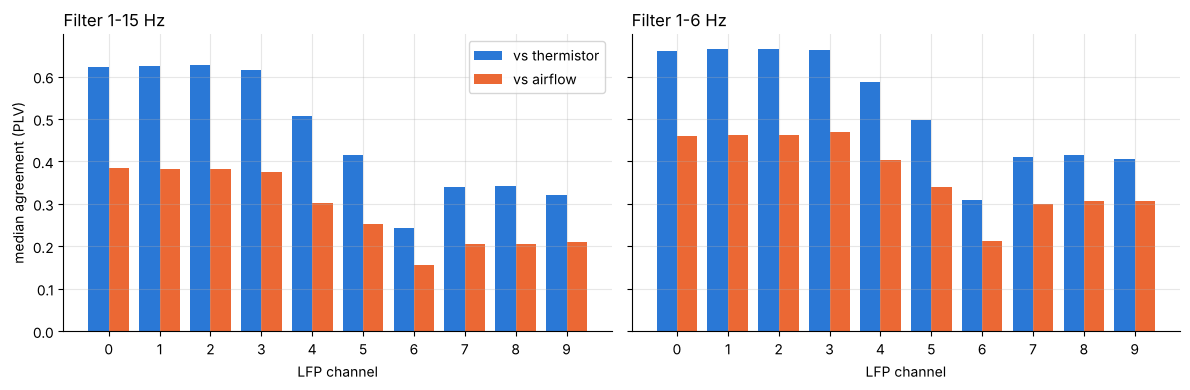

1-15 Hz   vs thermistor: 0.622 0.624 0.627 0.616 0.506 0.415 0.242 0.340 0.343 0.321
1-6 Hz   vs thermistor: 0.660 0.666 0.664 0.661 0.587 0.498 0.308 0.409 0.416 0.407


In [2]:
ph_th = {band: get_phase(thermistor, *band) for band in [(1, 15), (1, 6)]}
ph_af = {band: get_phase(airflow, *band)    for band in [(1, 15), (1, 6)]}

results = {}
for band in [(1, 15), (1, 6)]:
    ph_lfp = get_phase(lfp_all, *band)                  # all 10 channels at once
    results[band] = {
        "vs thermistor": [np.median(sliding_plv(ph_lfp[:, c], ph_th[band])[1]) for c in range(10)],
        "vs airflow":    [np.median(sliding_plv(ph_lfp[:, c], ph_af[band])[1]) for c in range(10)],
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, band in zip(axes, results):
    x = np.arange(10)
    ax.bar(x - 0.2, results[band]["vs thermistor"], 0.4, color=COLORS["Thermistor"], label="vs thermistor")
    ax.bar(x + 0.2, results[band]["vs airflow"],    0.4, color=COLORS["Airflow"],    label="vs airflow")
    ax.set_xticks(x); ax.set_xlabel("LFP channel"); ax.set_title(f"Filter {band[0]}-{band[1]} Hz", loc="left")
axes[0].set_ylabel("median agreement (PLV)"); axes[0].legend()
plt.tight_layout(); plt.show()

for band in results:
    print(f"{band[0]}-{band[1]} Hz   vs thermistor:", " ".join(f"{v:.3f}" for v in results[band]["vs thermistor"]))

**Result:**
- Channels **0–3 are tied** (0.62–0.63 vs thermistor in 1–15 Hz). The differences between them (~0.01) are far smaller than the variation between windows, so none of them is meaningfully "best."
- Agreement drops from channel 4 onward and is **lowest at channel 6**, where the breathing signal changes sign (section 3b of notebook 01).
- The ranking is the same in both bands and against both sensors.

**So channel 0 was a reasonable default from the best group, not a uniquely best channel.** Any of channels 0–3 would give the same results. An earlier test (averaging channels 0–2, or subtracting channel 8) also gave no improvement.

## 2. Why 5-second windows?

**Decision:** compute agreement (PLV) over 5-s windows.

**The concern with short windows:** PLV measures how steady the phase difference is. With only a few breaths in a window, two **unrelated** signals can look steady by chance. To measure that chance level, we compare the thermistor with the airflow **shifted by 60 s**, so the two can't genuinely be in step. Any agreement between them is pure chance.

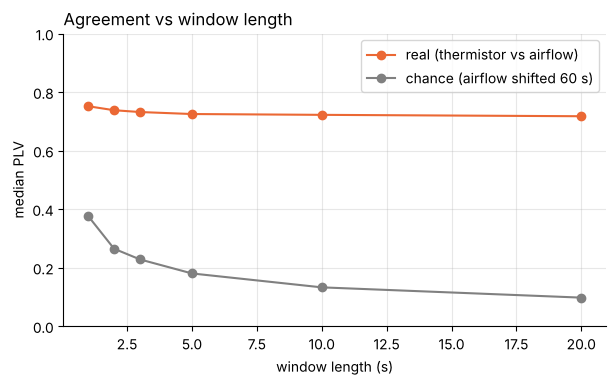

  1 s window: real 0.75   chance 0.38
  2 s window: real 0.74   chance 0.26
  3 s window: real 0.73   chance 0.23
  5 s window: real 0.72   chance 0.18
 10 s window: real 0.72   chance 0.13
 20 s window: real 0.72   chance 0.10


In [3]:
p_th, p_af = ph_th[(1, 15)], ph_af[(1, 15)]
p_af_shifted = np.roll(p_af, 60 * FS)        # airflow from 60 s later: unrelated by construction

wins = [1, 2, 3, 5, 10, 20]
real   = [np.median(sliding_plv(p_th, p_af,         w)[1]) for w in wins]
chance = [np.median(sliding_plv(p_th, p_af_shifted, w)[1]) for w in wins]

plt.figure(figsize=(7, 3.8))
plt.plot(wins, real, "o-", color=COLORS["Airflow"], label="real (thermistor vs airflow)")
plt.plot(wins, chance, "o-", color="0.5", label="chance (airflow shifted 60 s)")
plt.xlabel("window length (s)"); plt.ylabel("median PLV"); plt.ylim(0, 1); plt.legend()
plt.title("Agreement vs window length", loc="left"); plt.show()
for w, r, c in zip(wins, real, chance): print(f"{w:>3} s window: real {r:.2f}   chance {c:.2f}")

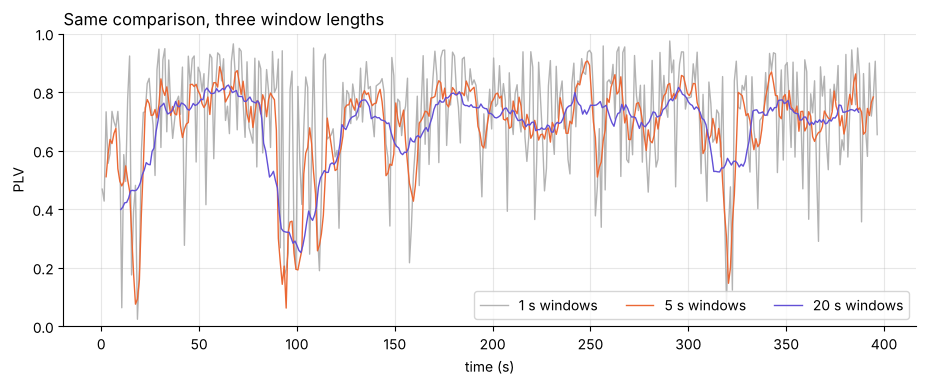

In [4]:
# Short vs long windows over time: short = noisy, long = smears the dips
fig, ax = plt.subplots(figsize=(11, 3.8))
for w, col in [(1, "0.7"), (5, COLORS["Airflow"]), (20, "#6250d6")]:
    c, v = sliding_plv(p_th, p_af, w)
    ax.plot(c + w / 2, v, color=col, lw=1, label=f"{w} s windows")
ax.set_ylim(0, 1); ax.set_xlabel("time (s)"); ax.set_ylabel("PLV"); ax.legend(ncol=3, loc="lower right")
ax.set_title("Same comparison, three window lengths", loc="left"); plt.show()

**Result:**
- **Chance agreement rises as windows shrink**: unrelated signals score 0.38 with 1-s windows but only 0.18 with 5-s windows. Short windows make a high score less meaningful.
- The time plot shows the other side: **1 s windows are jumpy**, while **20 s windows smear out** the short dips we care about.
- 5 s sits between these. It also matches the README's 5-s sleep-staging epochs. It's a reasonable trade-off, not an optimum: 3–10 s would lead to the same conclusions.

## 3. Which filter band?

**Decision:** 1–15 Hz. **This was the PI's choice, not mine**; the test below is why I'm raising it as a question.

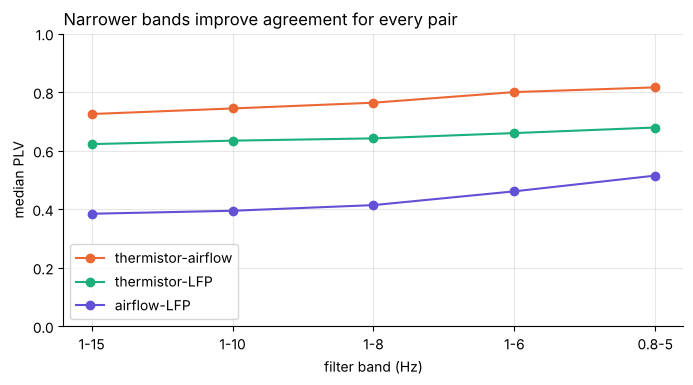

In [5]:
bands = [(1, 15), (1, 10), (1, 8), (1, 6), (0.8, 5)]
lfp0 = lfp_all[:, 0]
pairs = {"thermistor-airflow": (thermistor, airflow), "thermistor-LFP": (thermistor, lfp0), "airflow-LFP": (airflow, lfp0)}
table = {name: [] for name in pairs}
for lo, hi in bands:
    for name, (x, y) in pairs.items():
        table[name].append(np.median(sliding_plv(get_phase(x, lo, hi), get_phase(y, lo, hi))[1]))

plt.figure(figsize=(8, 3.8))
labels = [f"{lo}-{hi}" for lo, hi in bands]
for (name, vals), col in zip(table.items(), [COLORS["Airflow"], COLORS["LFP"], "#6250d6"]):
    plt.plot(labels, vals, "o-", color=col, label=name)
plt.xlabel("filter band (Hz)"); plt.ylabel("median PLV"); plt.ylim(0, 1); plt.legend()
plt.title("Narrower bands improve agreement for every pair", loc="left"); plt.show()

**Result:** every pair agrees more as the band narrows. Much of the 5–15 Hz content isn't shared between sensors.

**Caveat:** higher agreement doesn't automatically mean a better band. A narrow band also removes real fast breathing such as sniffing (6–12 Hz), and it forces the signals to look more alike. The PI may have chosen 15 Hz to keep sniffing. **This is a question for the PI, not a decision to make alone.**

## 4. Why `filtfilt`?

**Decision:** filter forward and then backward, instead of only forward.

**Test:** filter a clean 2 Hz wave both ways and compare the timing with the original.

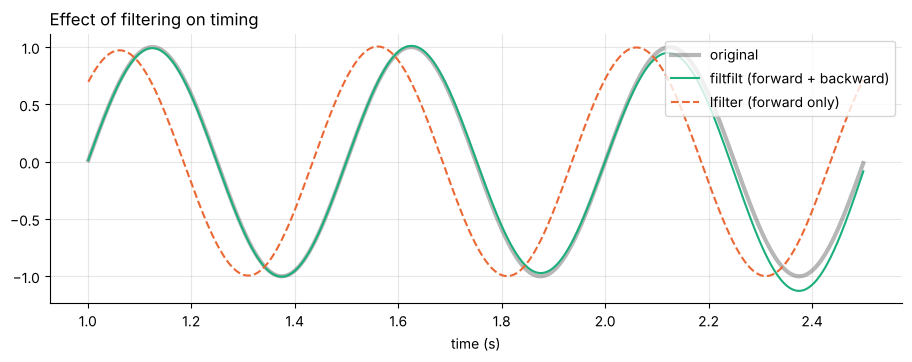

forward-only filter shifts the wave by about 64 ms; filtfilt shifts it by 0 ms


In [6]:
tt = np.arange(0, 3, 1 / FS)
wave = np.sin(2 * np.pi * 2 * tt)
b, a = signal.butter(3, [1, 15], btype="band", fs=FS)
one_way = signal.lfilter(b, a, wave)          # forward only
two_way = signal.filtfilt(b, a, wave)         # forward + backward

m = (tt > 1) & (tt < 2.5)
plt.plot(tt[m], wave[m], color="0.3", lw=3, alpha=0.4, label="original")
plt.plot(tt[m], two_way[m], color=COLORS["LFP"], label="filtfilt (forward + backward)")
plt.plot(tt[m], one_way[m], color=COLORS["Airflow"], ls="--", label="lfilter (forward only)")
plt.legend(loc="upper right"); plt.xlabel("time (s)"); plt.title("Effect of filtering on timing", loc="left"); plt.show()

lag = signal.correlation_lags(len(wave), len(wave))[np.argmax(signal.correlate(one_way, wave))]
print(f"forward-only filter shifts the wave by about {abs(lag)} ms; filtfilt shifts it by 0 ms")

**Result:** the forward-only filter shifts this 2 Hz wave by about 64 ms (here it moves it *earlier*); `filtfilt` lines up with the original. The size and direction of a one-way filter's shift **depend on frequency**, and each sensor contains a different mix of frequencies, so a one-way filter would shift each sensor's timing differently. Since this project compares **timing** across sensors, `filtfilt` is required, not optional.

(The small mismatch at the very right edge is an **edge effect**: every filter misbehaves in the last fraction of a second of a recording. On a 6.6-minute recording this only affects the first and last moments.)

## 5. Why Welch with 8,192-sample chunks?

**Decision:** `signal.welch(x, FS, nperseg=8192)`.

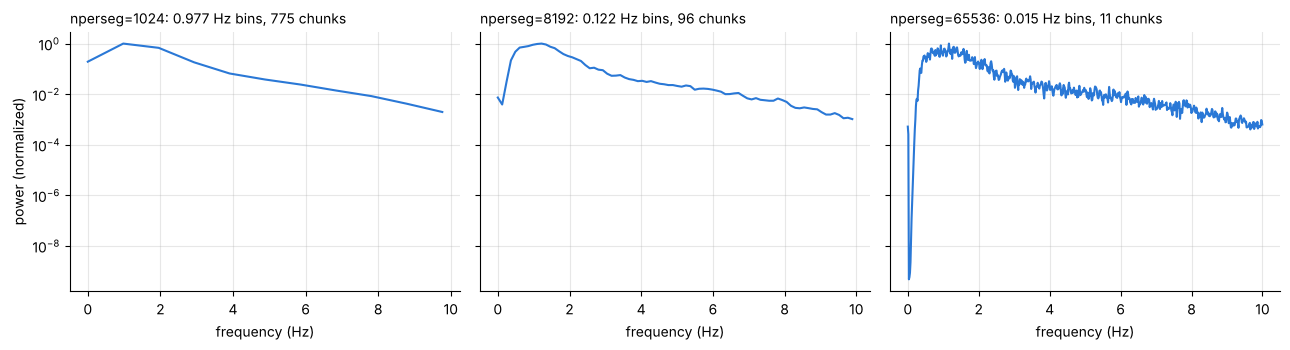

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, nps in zip(axes, [1024, 8192, 65536]):
    f, p = signal.welch(thermistor, FS, nperseg=nps)
    keep = f < 10
    ax.semilogy(f[keep], p[keep] / p[keep].max(), color=COLORS["Thermistor"])
    n_chunks = (len(thermistor) - nps // 2) // (nps // 2)
    ax.set_title(f"nperseg={nps}: {FS/nps:.3f} Hz bins, {n_chunks} chunks", loc="left", fontsize=10)
    ax.set_xlabel("frequency (Hz)")
axes[0].set_ylabel("power (normalized)"); plt.tight_layout(); plt.show()

**Result:** 1,024 is smooth but too coarse to locate the breathing peak (1 Hz bins); 65,536 is detailed but jagged (only 11 chunks to average). 8,192 gives 0.12 Hz bins with 96 chunks. As with the window length, it's a sensible middle, not an optimum.

## 6. Movement and quiet periods (the 90–100 s stretch)

**What notebook 01 implied:** the low-agreement stretch around 90–100 s is movement.

**Why it looks that way:** the overview EMG was smoothed with a **5-s** window, which spreads any short burst over 5 seconds. Here the EMG is shown at **0.25-s** resolution next to the strength (amplitude) of each breathing signal. Amplitude comes from the Hilbert transform: the distance of the point from the center of the circle.

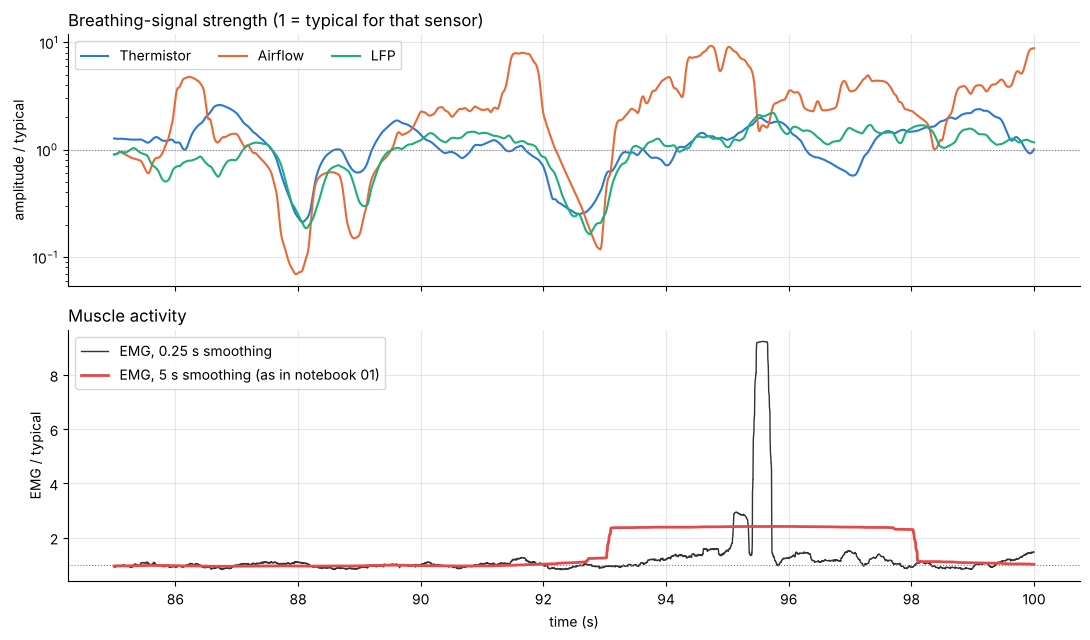

 time   therm  airflow  LFP   EMG(0.25s)
 88.0   0.23   0.07   0.25    1.09
 88.5   0.92   0.61   0.63    0.89
 89.0   0.61   0.16   0.33    0.88
 89.5   1.70   0.95   0.97    1.00
 90.0   1.38   2.25   1.22    1.00
 90.5   0.95   2.03   1.28    0.96
 91.0   1.10   2.34   1.43    1.03
 91.5   0.99   7.66   1.22    1.18
 92.0   0.69   2.16   0.85    0.97
 92.5   0.26   0.41   0.24    0.94
 93.0   0.54   0.30   0.25    0.93
 93.5   0.91   2.31   1.08    0.99
 94.0   0.72   4.62   1.08    1.20
 94.5   1.34   7.28   1.31    1.32
 95.0   1.23   8.85   1.05    1.53
 95.5   1.94   1.64   2.08    9.20
 96.0   1.56   3.49   1.42    1.27
 96.5   0.84   2.66   1.27    1.11
 97.0   0.58   3.51   1.59    1.51
 97.5   1.38   4.37   1.42    1.33
 98.0   1.47   2.29   1.58    0.91


In [8]:
def smooth(x, win_s):
    W = int(win_s * FS)
    return np.convolve(x, np.ones(W) / W, mode="same")

emg_hf = bandpass(emg, 30, 300)
emg_fine   = np.sqrt(smooth(emg_hf**2, 0.25))
emg_coarse = np.sqrt(smooth(emg_hf**2, 5))

amp = {name: smooth(np.abs(signal.hilbert(bandpass(x, 1, 15))), 0.5)
       for name, x in [("Thermistor", thermistor), ("Airflow", airflow), ("LFP", lfp0)]}

i0, i1 = 85 * FS, 100 * FS
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for name, a_ in amp.items():
    axes[0].plot(t[i0:i1], a_[i0:i1] / np.median(a_), color=COLORS[name], label=name)
axes[0].axhline(1, color="0.5", lw=0.8, ls=":")
axes[0].set_yscale("log"); axes[0].set_ylabel("amplitude / typical")
axes[0].set_title("Breathing-signal strength (1 = typical for that sensor)", loc="left"); axes[0].legend(ncol=3)
axes[1].plot(t[i0:i1], emg_fine[i0:i1] / np.median(emg_fine), color="0.2", lw=1, label="EMG, 0.25 s smoothing")
axes[1].plot(t[i0:i1], emg_coarse[i0:i1] / np.median(emg_coarse), color="#e34948", lw=2, label="EMG, 5 s smoothing (as in notebook 01)")
axes[1].axhline(1, color="0.5", lw=0.8, ls=":")
axes[1].set_ylabel("EMG / typical"); axes[1].set_xlabel("time (s)"); axes[1].legend()
axes[1].set_title("Muscle activity", loc="left")
plt.tight_layout(); plt.show()

print(" time   therm  airflow  LFP   EMG(0.25s)")
for s in np.arange(88, 98.5, 0.5):
    i = int(s * FS)
    print(f"{s:5.1f}  " + "  ".join(f"{amp[n][i]/np.median(amp[n]):5.2f}" for n in amp) + f"   {emg_fine[i]/np.median(emg_fine):5.2f}")

**Result:**
- **Muscle activity:** at fine resolution, the EMG is at its typical level from 88 to about 94 s, rises mildly from 94 to 97 s, and has **one sharp burst at about 95.5 s** (about 9× typical). With 5-s smoothing (red), that short burst gets spread into a broad hump, which is why the overview plot suggests movement across the whole stretch.
- **Quiet moments:** at **about 92.5–93 s (and also around 88 s)**, all three breathing signals drop to roughly a quarter of their typical strength **at the same time**, while the EMG stays at its typical level.

**Interpretation, with limits:**
- Three independent sensors going quiet together is more consistent with a **real pause in breathing** than with three sensors failing at once.
- "No muscle activity" means **no activity on this EMG electrode**, whose location we don't know. A movement that doesn't involve that muscle wouldn't show up. The video would settle it.
- The burst at 95.5 s lines up with the LFP's artifact burst, so that one is likely a contraction or movement.

## 7. Choosing the clean example window

**Original choice:** 246–251 s, ranked by thermistor–airflow agreement only.

**Test:** rank instead by the **weakest of the three pairs**, so a window counts as clean only if every pair agrees.

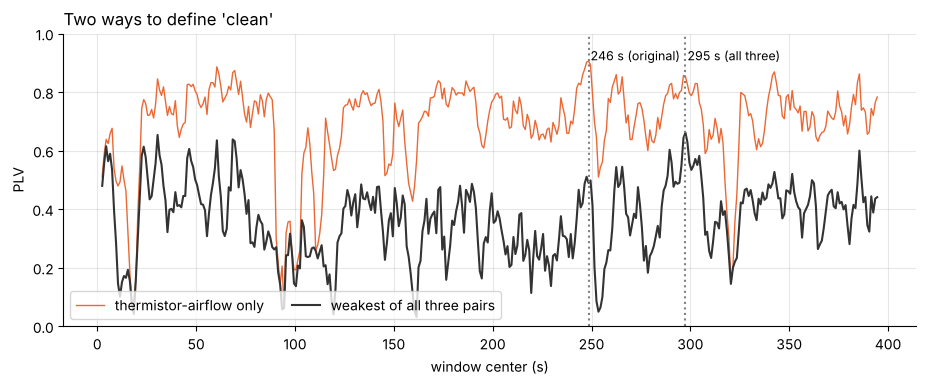

window 246-251 s:  th-af 0.91  th-LFP 0.65  af-LFP 0.49  weakest 0.49
window 295-300 s:  th-af 0.85  th-LFP 0.88  af-LFP 0.66  weakest 0.66


In [9]:
p_lfp = get_phase(lfp0)
c, ta = sliding_plv(p_th, p_af)
_, tl = sliding_plv(p_th, p_lfp)
_, al = sliding_plv(p_af, p_lfp)
weakest = np.minimum(np.minimum(ta, tl), al)

plt.figure(figsize=(11, 3.8))
centers = c + 2.5                      # sliding_plv returns window START times
plt.plot(centers, ta, color=COLORS["Airflow"], lw=1, label="thermistor-airflow only")
plt.plot(centers, weakest, color="0.2", lw=1.5, label="weakest of all three pairs")
for s, lab in [(246, "246 s (original)"), (295, "295 s (all three)")]:
    plt.axvline(s + 2.5, color="0.5", ls=":"); plt.text(s + 3.5, 0.95, lab, fontsize=9, va="top")
plt.ylim(0, 1); plt.xlabel("window center (s)"); plt.ylabel("PLV"); plt.legend(loc="lower left", ncol=2)
plt.title("Two ways to define 'clean'", loc="left"); plt.show()

for s in [246, 295]:
    i = np.argmin(np.abs(c - s))       # window starting at s
    print(f"window {s}-{s+5} s:  th-af {ta[i]:.2f}  th-LFP {tl[i]:.2f}  af-LFP {al[i]:.2f}  weakest {weakest[i]:.2f}")

**Result:** 246 s has the best thermistor–airflow agreement, but the LFP agrees poorly there. **295–300 s is the cleanest window for all three sensors**, and is the better example. Clean training data for the network should use the all-three definition.

## Summary of decisions

| Decision | Status after testing |
|---|---|
| LFP channel 0 | Fine, but tied with channels 1–3: a default, not a uniquely best channel |
| 5-s windows | Justified: chance agreement is low, dips stay visible |
| 1–15 Hz band | PI's choice; narrower bands agree better, but may remove sniffing → ask the PI |
| `filtfilt` | Required: one-way filtering shifts timing |
| Welch, 8,192 samples | Sensible middle ground |
| 90–100 s = movement | Only partly: one sharp muscle burst at ~95.5 s; a possible breathing pause at ~92.5–93 s with typical EMG |
| Clean example 246 s | Replaced by 295 s (all three sensors agree) |